# Tutorial 9: Autoencoders & Variational Autoencoders

Course: **Applied Deep Learning (ECE1553) - FALL 2026**
Instructor: **Dr. Ali Breyhi**
Tutorial: **Saleh Tabatabaei**

**You should already know:** basic PyTorch (tensors, `nn.Module`, a training loop) and the idea behind PCA.

| # | Section
|---|---|
| 0 | Setup: install packages, download MNIST
| 1 | Why autoencoders? Manifolds and PCA
| 2 | A basic autoencoder for MNIST compression
| 3 | The latent space of a single digit
| 4 | Generating digits by sampling the latent space, and why it fails
| 5 | The variational autoencoder: idea, code, training
| 6 | VAE results: sampling, latent map, interpolation
| 7 | Wrap-up, self-check, exercises
| ★ | *Bonus (homework):* a denoising autoencoder

---
## 0. Setup

### 0.1 Install dependencies
The cell below checks which packages are missing and installs only those. It is safe to re-run.

In [1]:
# Installs any missing package. Does nothing if everything is already installed.
import importlib.util, subprocess, sys

REQUIRED = {             # import name -> pip package name
    "torch": "torch",
    "torchvision": "torchvision",
    "numpy": "numpy",
    "matplotlib": "matplotlib",
    "PIL": "pillow",
}
missing = [pkg for module, pkg in REQUIRED.items() if importlib.util.find_spec(module) is None]
if missing:
    print("Installing:", ", ".join(missing), "... (the first time this can take a few minutes)")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", *missing])
    print("Done ✔")
else:
    print("All dependencies are already installed ✔")

All dependencies are already installed ✔


### 0.2 Imports, device and hyper-parameters
All the knobs you might want to change later are collected here.

In [2]:
import time
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision

# ---- Reproducibility --------------------------------------------------------
SEED = 0
torch.manual_seed(SEED)
np.random.seed(SEED)

# ---- Use the fastest device available ----------------------------------------
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():          # Apple Silicon
    device = torch.device("mps")
else:
    device = torch.device("cpu")

# ---- Hyper-parameters used throughout the notebook ---------------------------
LATENT_DIMS = 2     # size of the code z. We use 2 so that we can PLOT the latent space.
EPOCHS      = 10    # ~30-60 s per model on a laptop CPU. On a GPU, try 20+ for crisper results.
BATCH_SIZE  = 128
LR          = 1e-3  # Adam learning rate

plt.rcParams.update({"figure.dpi": 100, "image.cmap": "gray", "axes.titlesize": 11})
print(f"PyTorch {torch.__version__} | running on: {device}")

PyTorch 2.14.1+cu130 | running on: cuda


In [3]:
# ---- Small plotting helpers used everywhere below ----------------------------
def show_images(images, ncols=8, title=None, ax=None):
    """Draw a batch of images with shape (N, 1, 28, 28) as a single grid."""
    images = images.detach().cpu()
    grid = torchvision.utils.make_grid(images, nrow=ncols, padding=2, pad_value=1.0)
    if ax is None:
        nrows = (len(images) + ncols - 1) // ncols
        _, ax = plt.subplots(figsize=(0.6 * ncols, 0.6 * nrows + 0.4))
    ax.imshow(grid.permute(1, 2, 0))
    ax.set_axis_off()
    if title:
        ax.set_title(title)
    return ax


# tab10 colours, except digit 7 gets navy instead of grey (grey is reserved for "everything else")
DIGIT_COLORS = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd",
                "#8c564b", "#e377c2", "#000080", "#bcbd22", "#17becf"]

def plot_latent(Z, labels, ax=None, title="", only_digit=None, s=3):
    """Scatter plot of 2-D latent codes, coloured by digit label.
    If `only_digit` is set, that digit is coloured and everything else is grey."""
    Z, labels = Z.cpu(), labels.cpu()
    if ax is None:
        _, ax = plt.subplots(figsize=(6, 5))
    if only_digit is not None:                                  # grey background first ...
        m = labels != only_digit
        ax.scatter(Z[m, 0], Z[m, 1], s=s, color="#dddddd")
    for d in range(10):                                        # ... coloured digits on top
        if only_digit is None or d == only_digit:
            m = labels == d
            ax.scatter(Z[m, 0], Z[m, 1], s=s, color=DIGIT_COLORS[d], label=str(d))
    ax.legend(markerscale=4, fontsize=8, title="digit", loc="best", framealpha=0.8)
    ax.set_xlabel("$z_1$"); ax.set_ylabel("$z_2$"); ax.set_title(title)
    return ax

### 0.3 Download MNIST
MNIST has **70,000** handwritten digits (60,000 for training, 10,000 for testing). Each one is a 28×28 grayscale image.

`torchvision` downloads it the first time and caches it in `./data`. We give it several mirrors, so the download still works if one server is down or blocked.

> 💡 **Why not use a `DataLoader`?** MNIST is tiny (about 200 MB as floats), so we keep the whole dataset in memory as one tensor and slice mini-batches out of it ourselves. On a CPU this is about 10× faster than `DataLoader` + `ToTensor`, and you get more time for the interesting parts.

In [4]:
# torchvision tries these mirrors in order (the files and checksums are identical).
torchvision.datasets.MNIST.mirrors = [
    "https://ossci-datasets.s3.amazonaws.com/mnist/",          # PyTorch's official mirror
    "https://raw.githubusercontent.com/fgnt/mnist/master/",    # GitHub copy
    "http://yann.lecun.com/exdb/mnist/",                       # original source (often offline)
]

def load_mnist(root="./data"):
    """Download MNIST (once) and return float tensors with pixel values in [0, 1]."""
    out = []
    for train in (True, False):
        ds = torchvision.datasets.MNIST(root, train=train, download=True)
        X = ds.data.float().div(255).unsqueeze(1)    # (N, 1, 28, 28)
        y = ds.targets                                # (N,) labels 0-9 (only used for plots!)
        out += [X, y]
    return out

X_train, y_train, X_test, y_test = load_mnist()
print("train images:", tuple(X_train.shape), "| test images:", tuple(X_test.shape))
print("pixel values range from", X_train.min().item(), "to", X_train.max().item())

100%|██████████| 9.91M/9.91M [00:00<00:00, 9.98MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.52MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 10.5MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 2.51MB/s]


train images: (60000, 1, 28, 28) | test images: (10000, 1, 28, 28)
pixel values range from 0.0 to 1.0


labels: [5, 0, 4, 1, 9, 2, 1, 3, 1, 4, 3, 5, 3, 6, 1, 7, 2, 8, 6, 9, 4, 0, 9, 1, 1, 2, 4, 3, 2, 7, 3, 8]


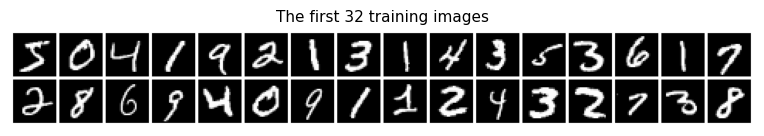

In [5]:
show_images(X_train[:32], ncols=16, title="The first 32 training images")
print("labels:", y_train[:32].tolist())

---
## 1. Why autoencoders?

### 1.1 The manifold hypothesis
> **Manifold hypothesis:** real-world high-dimensional data lies on (or close to) a **low-dimensional manifold** inside the high-dimensional space.

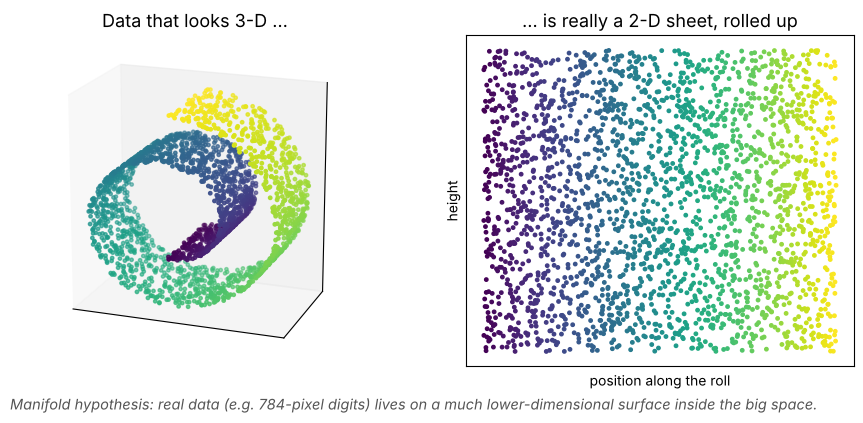

An MNIST image is a point in a **784-dimensional** space, with one axis per pixel. But almost every point in that space is meaningless static. Let's check:

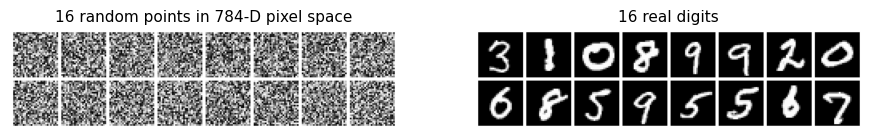

In [6]:
random_points = torch.rand(16, 1, 28, 28)                         # 16 random points in pixel space
real_digits   = X_train[torch.randint(len(X_train), (16,))]       # 16 real digits

fig, axes = plt.subplots(1, 2, figsize=(11, 2.8))
show_images(random_points, ncols=8, title="16 random points in 784-D pixel space", ax=axes[0])
show_images(real_digits,   ncols=8, title="16 real digits", ax=axes[1])
plt.show()

You could sample random pixel images until the end of the universe and never draw a "7". Real digits occupy a tiny, thin, curved region of pixel space. If we can find **coordinates on that region**, we can describe each digit with a handful of numbers instead of 784.

**That is exactly what an autoencoder learns.**

### 1.2 From PCA to autoencoders
In **PCA** we compress with a *linear* map and decompress with its transpose:

$$z = W(x - \bar{x}) \qquad\qquad \hat{x} = W^\top z + \bar{x}$$

PCA picks the $W$ that minimises the reconstruction error $\lVert x - \hat{x} \rVert^2$. But it can only find **flat** subspaces, and our manifold is curved.

An **autoencoder** keeps the same idea and replaces both linear maps with **neural networks**:

$$z = f_\theta(x) \;\; \text{(encoder)} \qquad\qquad \hat{x} = g_\phi(z) \;\; \text{(decoder)} \qquad\qquad \min_{\theta,\phi}\; \mathcal{L}\big(x,\, g_\phi(f_\theta(x))\big)$$

The task is simply **"given $x$, predict $x$"**. No labels are needed, so autoencoders are *self-supervised*.

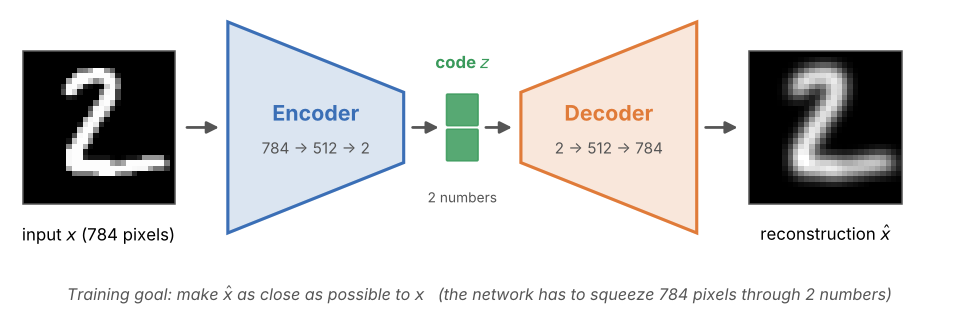

**Why use neural networks instead of PCA?**
* **Non-linear:** they can follow a curved manifold.
* **Deep:** they can learn abstract features (strokes, loops, slant).
* **Flexible:** the encoder and decoder don't have to mirror each other. You could use a CNN encoder with an MLP decoder, for example.

| Term | Meaning |
|---|---|
| **Encoder** $f_\theta$ | network that compresses $x$ into a code $z$ |
| **Latent code** $z$ | the compressed representation (also called the *embedding* or *bottleneck*) |
| **Latent space** | the space of all possible codes; here $\mathbb{R}^2$ |
| **Decoder** $g_\phi$ | network that maps a code back to an image $\hat{x}$ |
| **Reconstruction loss** | how different $\hat{x}$ is from $x$ |

> 🗣 **Quick question for the class:** if the code $z$ had 784 dimensions, what would the network learn? *(Think about it, then read on.)*
>
> It could just learn to **copy** the input. The **bottleneck** is what forces it to discover structure.

---
## 2. A basic autoencoder for MNIST compression

### 2.1 The model
We use two small fully-connected networks:

* **Encoder:** 784 → 512 (ReLU) → 2
* **Decoder:** 2 → 512 (ReLU) → 784 (**sigmoid**, so that every output pixel is in $[0, 1]$ like the input)

In [7]:
class Encoder(nn.Module):
    """x (B, 1, 28, 28)  ->  z (B, latent_dims)"""
    def __init__(self, latent_dims):
        super().__init__()
        self.hidden = nn.Linear(28 * 28, 512)
        self.to_z   = nn.Linear(512, latent_dims)

    def forward(self, x):
        x = torch.flatten(x, start_dim=1)          # (B, 784)
        h = F.relu(self.hidden(x))                 # (B, 512)
        return self.to_z(h)                        # (B, latent_dims), no activation: z can be any real number


class Decoder(nn.Module):
    """z (B, latent_dims)  ->  x_hat (B, 1, 28, 28)"""
    def __init__(self, latent_dims):
        super().__init__()
        self.hidden    = nn.Linear(latent_dims, 512)
        self.to_pixels = nn.Linear(512, 28 * 28)

    def forward(self, z):
        h = F.relu(self.hidden(z))
        x_hat = torch.sigmoid(self.to_pixels(h))   # pixel values in [0, 1]
        return x_hat.view(-1, 1, 28, 28)


class Autoencoder(nn.Module):
    def __init__(self, latent_dims):
        super().__init__()
        self.encoder = Encoder(latent_dims)
        self.decoder = Decoder(latent_dims)

    def forward(self, x):
        z = self.encoder(x)
        return self.decoder(z)

In [8]:
torch.manual_seed(SEED)
autoencoder = Autoencoder(LATENT_DIMS).to(device)
print(autoencoder)
print(f"\n{sum(p.numel() for p in autoencoder.parameters()):,} trainable parameters")

# Sanity check: always push a tiny batch through a new model and look at the shapes
x = X_train[:5].to(device)
z = autoencoder.encoder(x)
x_hat = autoencoder.decoder(z)
print(f"\nx {tuple(x.shape)}  →  z {tuple(z.shape)}  →  x̂ {tuple(x_hat.shape)}")

Autoencoder(
  (encoder): Encoder(
    (hidden): Linear(in_features=784, out_features=512, bias=True)
    (to_z): Linear(in_features=512, out_features=2, bias=True)
  )
  (decoder): Decoder(
    (hidden): Linear(in_features=2, out_features=512, bias=True)
    (to_pixels): Linear(in_features=512, out_features=784, bias=True)
  )
)

806,674 trainable parameters

x (5, 1, 28, 28)  →  z (5, 2)  →  x̂ (5, 1, 28, 28)


### 2.2 The loss: how good is a reconstruction?
Pixels are in $[0, 1]$, so we treat each output pixel as *"the probability that this pixel is ink"* and use **binary cross-entropy (BCE)**, summed over the 784 pixels:

$$\mathcal{L}_{\text{rec}}(x, \hat{x}) = -\sum_{i=1}^{784} \Big[ x_i \log \hat{x}_i + (1 - x_i) \log (1 - \hat{x}_i) \Big]$$

We then average this over the images in a mini-batch. *(The mean squared error $\lVert x - \hat{x}\rVert^2$ also works. Try it in the exercises.)*

Each loss function returns a **dict**. The entry `"loss"` is what gets minimised, and any other entries are only logged. This lets one training loop serve every model in this notebook.

In [9]:
def reconstruction_loss(x_hat, x):
    """Binary cross-entropy summed over the 784 pixels, averaged over the batch."""
    return F.binary_cross_entropy(x_hat, x, reduction="sum") / x.shape[0]


def ae_loss(model, x):
    x_hat = model(x)
    return {"loss": reconstruction_loss(x_hat, x)}

### 2.3 The training loop
This is a standard mini-batch loop with the Adam optimiser. We'll reuse it unchanged for the VAE.

In [10]:
def train(model, loss_fn, epochs=None, batch_size=BATCH_SIZE, lr=LR):
    """Trains `model` by minimising loss_fn(model, x)["loss"]. Returns the per-epoch averages of all loss terms."""
    epochs = epochs or EPOCHS
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    history = {}
    model.train()
    for epoch in range(1, epochs + 1):
        start, sums = time.time(), {}
        perm = torch.randperm(len(X_train))                    # new random order every epoch
        for i in range(0, len(X_train), batch_size):
            x = X_train[perm[i:i + batch_size]].to(device)     # one mini-batch

            losses = loss_fn(model, x)                         # 1. forward pass + loss
            opt.zero_grad()                                    # 2. reset old gradients
            losses["loss"].backward()                          # 3. back-propagate
            opt.step()                                         # 4. update weights

            for k, v in losses.items():
                sums[k] = sums.get(k, 0.0) + v.item() * len(x)
        for k, v in sums.items():
            history.setdefault(k, []).append(v / len(X_train))
        log = "  ".join(f"{k} {vals[-1]:7.2f}" for k, vals in history.items())
        print(f"epoch {epoch:2d}/{epochs} | {log} | {time.time() - start:4.1f}s")
    model.eval()
    return history

### 2.4 Train it! (~30–60 s on a CPU)
> 🗣 *While it trains:* the network never sees a label. It only tries to redraw its input after squeezing it through **2 numbers**. What do you expect those 2 numbers to capture?

In [11]:
ae_history = train(autoencoder, ae_loss)

epoch  1/10 | loss  179.40 | 12.4s
epoch  2/10 | loss  159.57 |  1.6s
epoch  3/10 | loss  155.26 |  1.3s
epoch  4/10 | loss  152.67 |  1.5s
epoch  5/10 | loss  150.67 |  1.4s
epoch  6/10 | loss  149.14 |  1.4s
epoch  7/10 | loss  147.91 |  1.5s
epoch  8/10 | loss  146.88 |  1.2s
epoch  9/10 | loss  145.96 |  1.2s
epoch 10/10 | loss  145.20 |  1.2s


### 2.5 How good is the compression?
Let's reconstruct **test** digits, which the network has never seen. As a baseline we use **PCA with the same 2 numbers per image**, which is the best possible *linear* autoencoder.

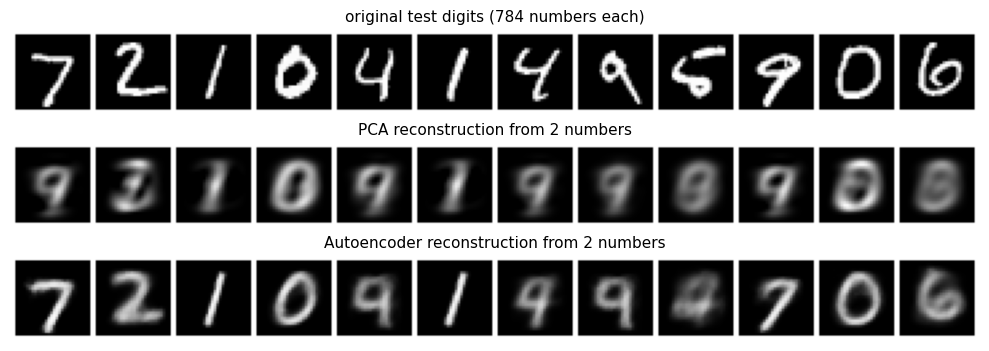

Compression ratio: 784 → 2 numbers = 392x smaller
Squared error per test image   PCA: 43.5   Autoencoder: 32.8   (lower is better)


In [12]:
# ---- PCA baseline with LATENT_DIMS components (= best LINEAR encoder/decoder) ----
X_flat = X_train.flatten(1)
pixel_mean = X_flat.mean(0)
cov = (X_flat - pixel_mean).T @ (X_flat - pixel_mean) / len(X_flat)   # (784, 784) covariance matrix
eigvals, eigvecs = torch.linalg.eigh(cov)                             # eigenvalues in ascending order
W = eigvecs[:, -LATENT_DIMS:].T                                       # top principal directions (k, 784)

def pca_reconstruct(x):
    z = (x.flatten(1) - pixel_mean) @ W.T                 # encode: z = W (x - mean)
    x_hat = z @ W + pixel_mean                            # decode: x̂ = Wᵀ z + mean
    return x_hat.clamp(0, 1).view(-1, 1, 28, 28)

def mse_per_image(x_hat, x):
    return ((x_hat - x) ** 2).flatten(1).sum(1).mean().item()

# ---- Compare on the test set ----
with torch.no_grad():
    ae_test  = autoencoder(X_test.to(device)).cpu()
pca_test = pca_reconstruct(X_test)

n = 12
fig, axes = plt.subplots(3, 1, figsize=(10, 3.6))
show_images(X_test[:n],   ncols=n, ax=axes[0], title="original test digits (784 numbers each)")
show_images(pca_test[:n], ncols=n, ax=axes[1], title=f"PCA reconstruction from {LATENT_DIMS} numbers")
show_images(ae_test[:n],  ncols=n, ax=axes[2], title=f"Autoencoder reconstruction from {LATENT_DIMS} numbers")
plt.tight_layout(); plt.show()

print(f"Compression ratio: 784 → {LATENT_DIMS} numbers = {784 / LATENT_DIMS:.0f}x smaller")
print(f"Squared error per test image   PCA: {mse_per_image(pca_test, X_test):.1f}   "
      f"Autoencoder: {mse_per_image(ae_test, X_test):.1f}   (lower is better)")

**Takeaways**
* With the same 2 numbers, the **non-linear autoencoder clearly beats linear PCA**.
* The reconstructions are still **blurry**. Two numbers can store *which* digit it is and roughly *how* it's written, but not every stroke. Increase `LATENT_DIMS` to 16 and the reconstructions become sharp. *(Exercise 1. The catch is that you can no longer plot the latent space directly.)*

---
## 3. The latent space of a single digit

### 3.1 One digit → two numbers → one digit
Let's follow **one** test image through the network.

label: 7
its entire latent code: z = [  7.29 -17.07]


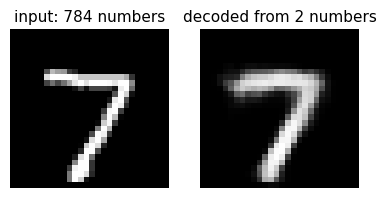

In [13]:
idx = 0                                         # 👈 try other indices!
x_single = X_test[idx:idx + 1].to(device)       # shape (1, 1, 28, 28)

with torch.no_grad():
    z_single = autoencoder.encoder(x_single)    # shape (1, 2)
    x_single_hat = autoencoder.decoder(z_single)

print(f"label: {y_test[idx].item()}")
print(f"its entire latent code: z = {z_single.squeeze().cpu().numpy().round(2)}")

fig, axes = plt.subplots(1, 2, figsize=(4.5, 2.4))
axes[0].imshow(x_single.squeeze().cpu()); axes[0].set_title("input: 784 numbers")
axes[1].imshow(x_single_hat.squeeze().cpu()); axes[1].set_title("decoded from 2 numbers")
for a in axes: a.axis("off")
plt.show()

### 3.2 Where does this digit live?
Now we encode all 10,000 test digits and plot their codes. Colours show the true label, which the autoencoder **never saw**. The ★ is our single digit from above.

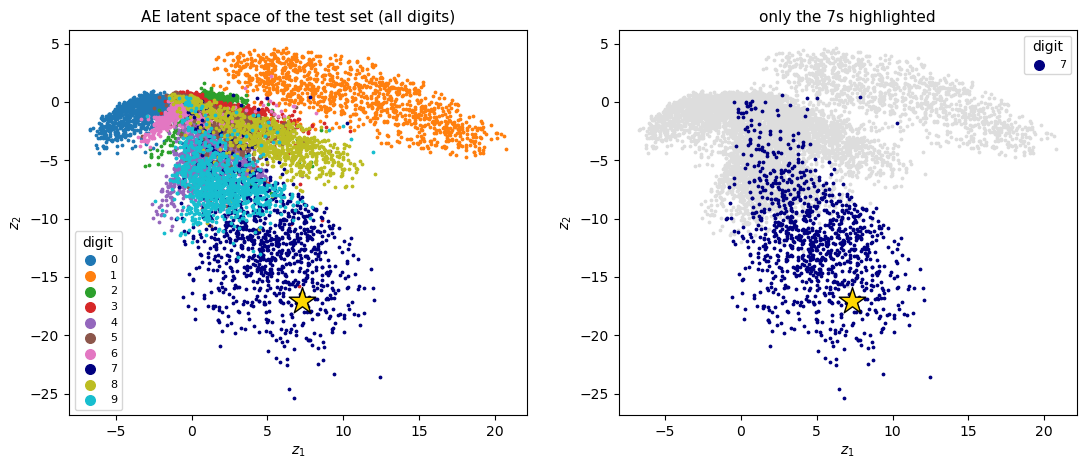

In [14]:
@torch.no_grad()
def encode(model, X):
    """Latent codes of a whole dataset (for the VAE later: the mean μ, no sampling)."""
    out = model.encoder(X.to(device))
    return (out[0] if isinstance(out, tuple) else out).cpu()

Z_ae = encode(autoencoder, X_test)
z0 = z_single.squeeze().cpu()
digit = y_test[idx].item()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
plot_latent(Z_ae, y_test, ax=axes[0], title="AE latent space of the test set (all digits)")
plot_latent(Z_ae, y_test, ax=axes[1], only_digit=digit, title=f"only the {digit}s highlighted")
for ax in axes:
    ax.scatter(*z0, marker="*", s=400, c="gold", edgecolors="k", zorder=5)
plt.show()

**What do you notice?**
* Digits of the same class **cluster together**, even though no labels were used. The autoencoder discovered the classes by itself because that is the most useful information to keep when you only have 2 numbers.
* Some clusters are well separated (often 0 and 1) and others overlap (4/9, 3/5/8). Those are the digits that look alike.
* Each class covers a **region**, not a point. Position inside the region encodes *style*: slant, thickness, size.

### 3.3 Zooming in: the neighbourhood of our digit
What does the decoder produce **near** our digit's code? We decode a small grid of points centred on ★.

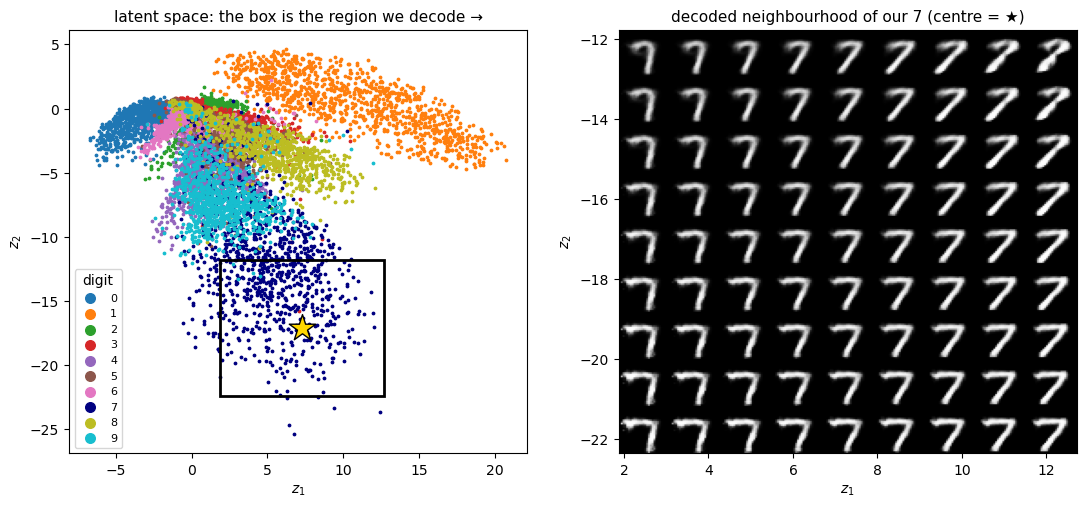

In [15]:
@torch.no_grad()
def plot_latent_grid(model, xlim, ylim, n=15, ax=None, title=""):
    """Decode an n×n grid of 2-D latent points and tile the images into a 'map' of the latent space."""
    xs = torch.linspace(*xlim, n)
    ys = torch.linspace(*ylim, n).flip(0)                    # top row = largest z2
    grid = torch.stack(torch.meshgrid(xs, ys, indexing="xy"), dim=-1).reshape(-1, 2)
    imgs = model.decoder(grid.to(device)).cpu().view(n, n, 28, 28)
    tiled = imgs.permute(0, 2, 1, 3).reshape(n * 28, n * 28)
    if ax is None:
        _, ax = plt.subplots(figsize=(6, 6))
    ax.imshow(tiled, extent=[*xlim, *ylim], aspect="auto")
    ax.set_xlabel("$z_1$"); ax.set_ylabel("$z_2$"); ax.set_title(title)
    return ax

zx, zy = z0.tolist()                                          # centre = our digit's code
rx, ry = (1.25 * Z_ae.std(0)).tolist()                        # neighbourhood radius per axis
xlim, ylim = (zx - rx, zx + rx), (zy - ry, zy + ry)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
plot_latent(Z_ae, y_test, ax=axes[0], title="latent space: the box is the region we decode →")
axes[0].scatter(*z0, marker="*", s=400, c="gold", edgecolors="k", zorder=5)
axes[0].add_patch(plt.Rectangle((xlim[0], ylim[0]), 2 * rx, 2 * ry, fill=False, lw=2, ec="k", zorder=6))
plot_latent_grid(autoencoder, xlim, ylim, n=9, ax=axes[1], title=f"decoded neighbourhood of our {digit} (centre = ★)")
plt.show()

Close to real data the decoder behaves nicely. Small steps in $z$ give small, gradual changes in the image (slant, width, thickness). Further away, the digit slowly morphs into a neighbouring class or gets stretched out of shape.

---
## 4. Generating digits by sampling the latent space, and why it fails

The decoder turns **any** 2 numbers into an image. So here's a tempting idea for a **generative model**:

> *Pick a random $z$ → decode it → a brand-new digit!*

The question is **which** random $z$. Let's try the most standard choice first: $z \sim \mathcal{N}(0, I)$.

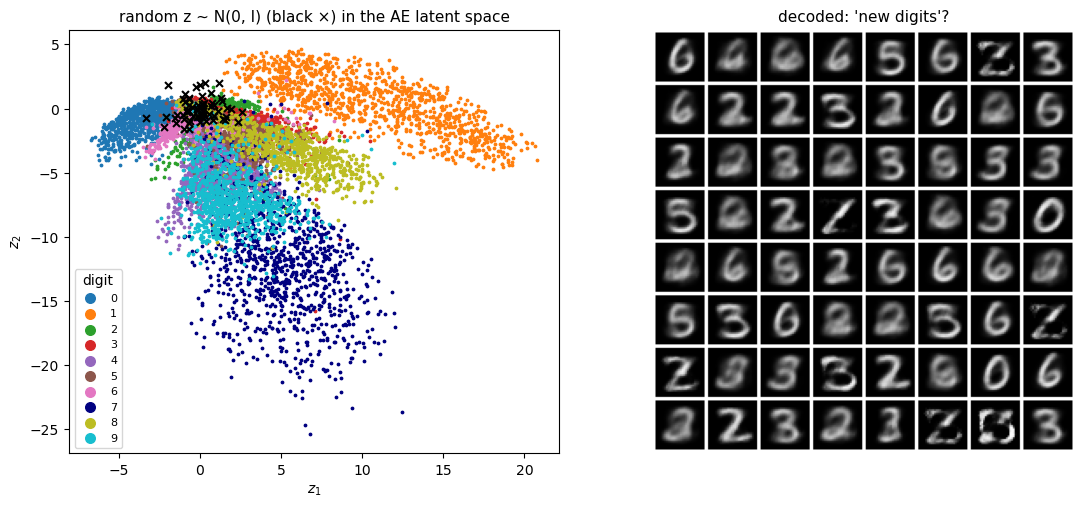

In [16]:
torch.manual_seed(1)
z_random = torch.randn(64, LATENT_DIMS)                 # 64 samples from N(0, I)
with torch.no_grad():
    samples_ae = autoencoder.decoder(z_random.to(device))

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), gridspec_kw={"width_ratios": [1.15, 1]})
plot_latent(Z_ae, y_test, ax=axes[0], title="random z ~ N(0, I) (black ×) in the AE latent space")
axes[0].scatter(*z_random.T, c="k", marker="x", s=25, zorder=5)
show_images(samples_ae, ncols=8, ax=axes[1], title="decoded: 'new digits'?")
plt.show()

**Attempt 1 failed.** The samples bunch up in one small patch of the latent space, so we only get a few kinds of digit, and many of them are blurry mixtures. $\mathcal{N}(0, I)$ means nothing to the autoencoder. Nothing in its loss told it to put its codes there, or at any particular scale. Look at the axes: the codes span tens of units.

**Attempt 2: be smarter.** Let's sample uniformly over the whole rectangle that the training codes occupy.

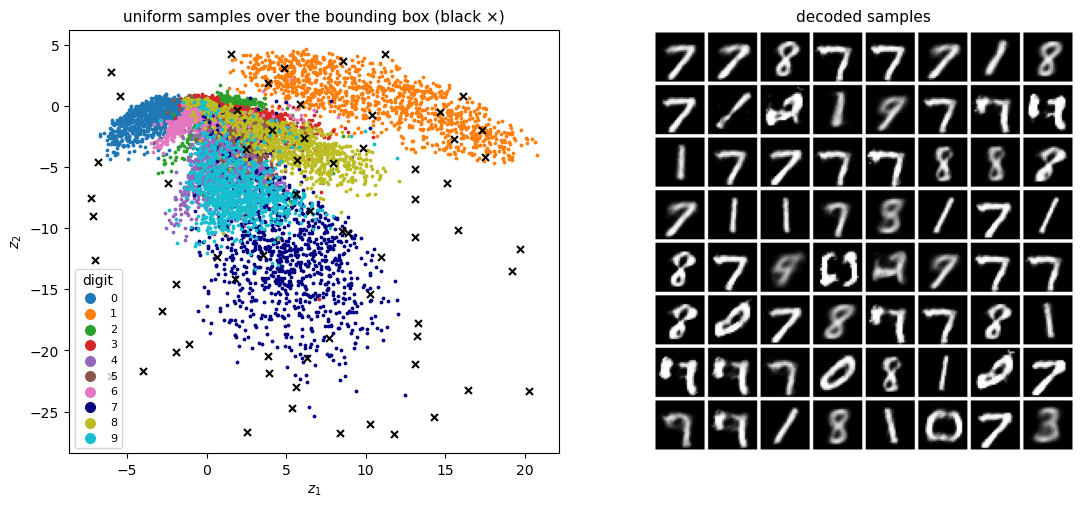

In [17]:
Z_train_ae = encode(autoencoder, X_train)
lo, hi = Z_train_ae.min(0).values, Z_train_ae.max(0).values
torch.manual_seed(2)
z_box = lo + (hi - lo) * torch.rand(64, LATENT_DIMS)    # uniform over the bounding box
with torch.no_grad():
    samples_box = autoencoder.decoder(z_box.to(device))

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), gridspec_kw={"width_ratios": [1.15, 1]})
plot_latent(Z_ae, y_test, ax=axes[0], title="uniform samples over the bounding box (black ×)")
axes[0].scatter(*z_box.T, c="k", marker="x", s=25, zorder=5)
show_images(samples_box, ncols=8, ax=axes[1], title="decoded samples")
plt.show()

There's more variety now, but look closely:
* Digits whose clusters cover a **large area** show up far more often than the others, simply because they take up more space.
* Samples that land in **empty space**, between or outside the clusters, come out as blobs, broken strokes or over-stretched digits. The decoder never saw a training code there.

To see the whole picture, let's decode a grid that covers the **entire** latent space:

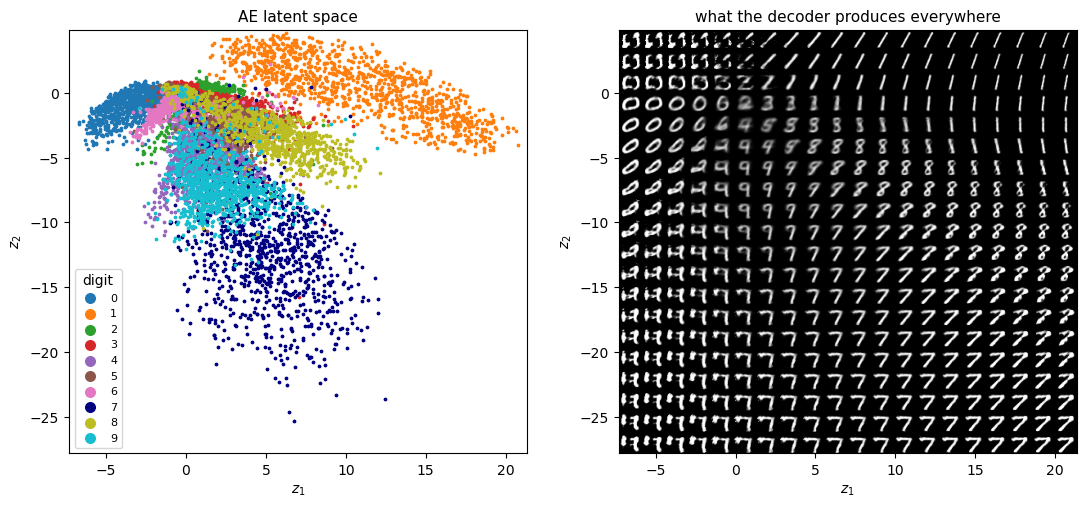

In [18]:
xlim, ylim = (lo[0].item(), hi[0].item()), (lo[1].item(), hi[1].item())
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
plot_latent(Z_ae, y_test, ax=axes[0], title="AE latent space")
axes[0].set_xlim(*xlim); axes[0].set_ylim(*ylim)
plot_latent_grid(autoencoder, xlim, ylim, n=20, ax=axes[1], title="what the decoder produces everywhere")
plt.show()

On this map you'll typically find large areas that all decode to one stretched-out digit, blurry mixtures where clusters overlap, and broken scribbles near the edges.

### Why sampling a plain autoencoder doesn't work
The autoencoder was trained only to reconstruct, so it only cares about the **exact points** where training codes landed. Nothing else was asked of the latent space:

1. **No known distribution.** We don't know *where* to sample. The codes can sit anywhere, at any scale, and they aren't centred.
2. **Gaps.** There are empty regions between and around clusters. Decoding a point there gives garbage, because the decoder never saw it during training.
3. **No guaranteed continuity.** Two nearby codes can decode to very different images. Being close in latent space doesn't have to mean being similar in data space.

To get a good generator, we need a latent space that (1) follows a **known distribution** we can sample from, (2) has **no holes**, and (3) is **smooth**.

➡️ **This is exactly what the variational autoencoder adds.**

---
## 5. The variational autoencoder (VAE)

### 5.1 The idea: encode each image as a cloud, not a point
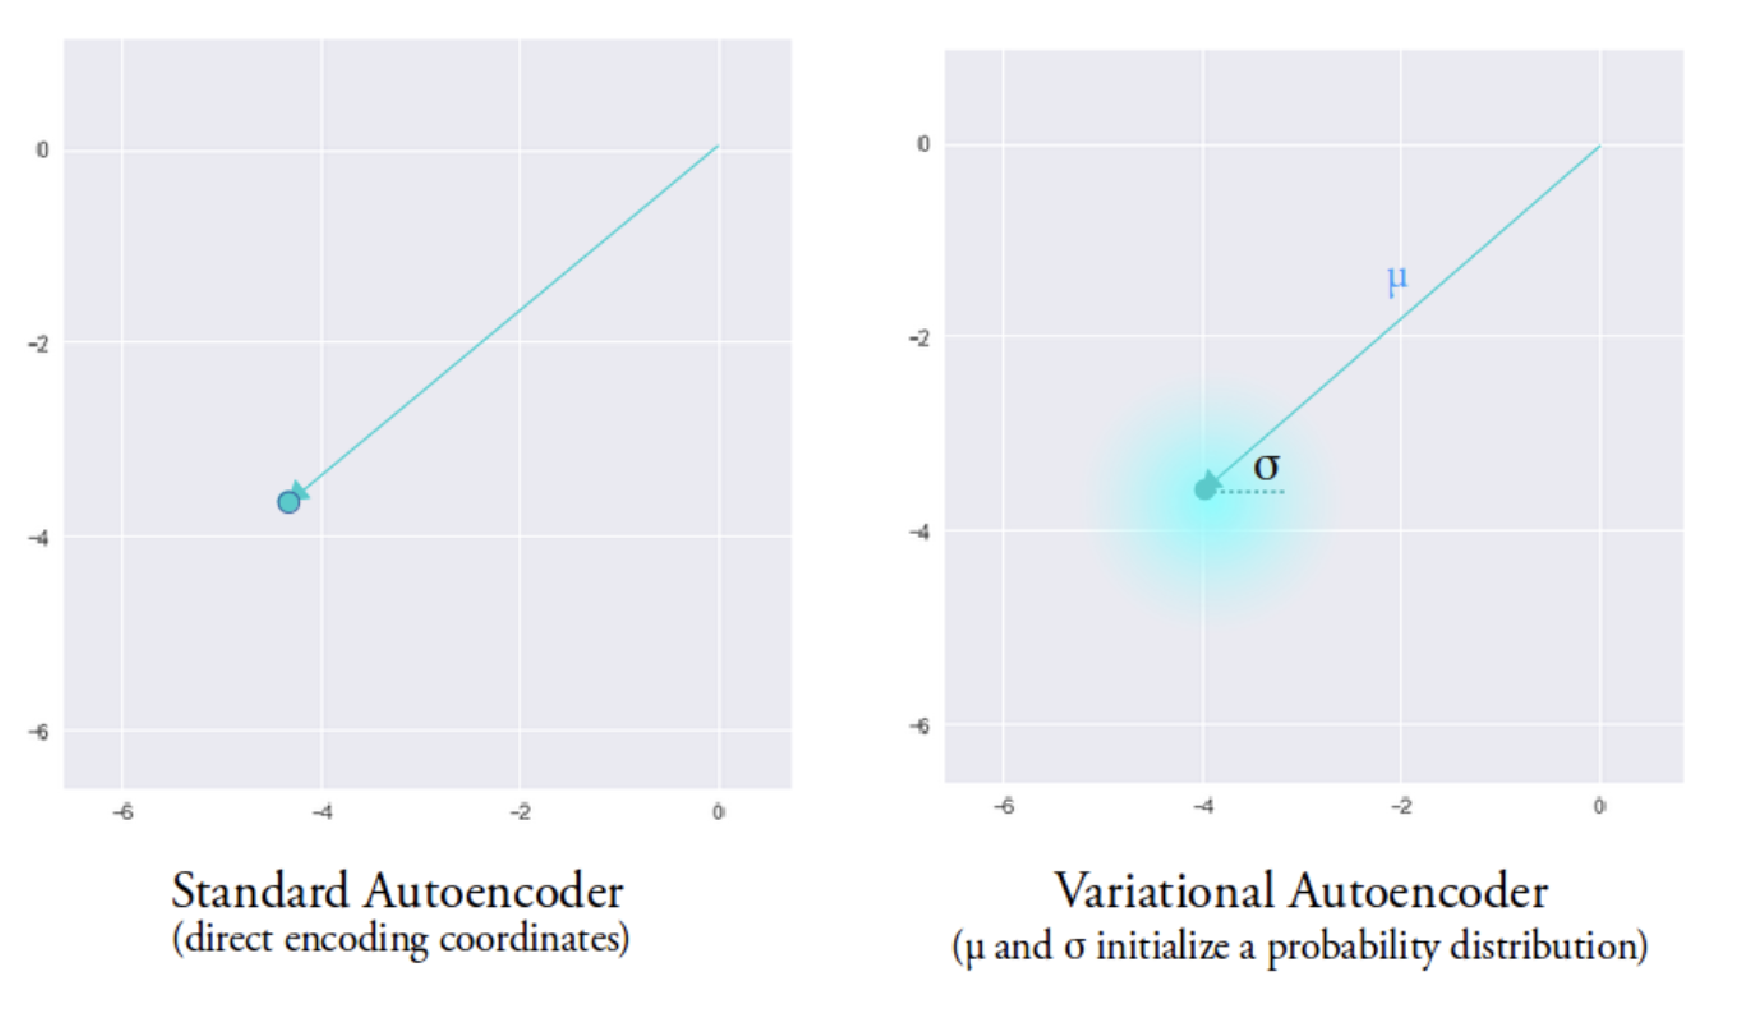

A VAE makes two changes to the autoencoder.

**Change 1: encode with uncertainty.** The encoder no longer outputs a point. It outputs the parameters of a small Gaussian *cloud*: a vector of **means $\mu$** and a vector of **standard deviations $\sigma$**. During training we **sample** $z$ from that cloud and decode the sample:

$$z \sim \mathcal{N}\big(\mu(x),\ \sigma(x)^2\big)$$

The decoder now sees a slightly different $z$ for the same image every time, so it has to decode **the whole neighbourhood** of each code into something sensible. That **fills the gaps** and makes the space **smooth**.

**Change 2: pull every cloud towards $\mathcal{N}(0, I)$.** We add a penalty to the loss, the **KL divergence**, that measures how far each cloud is from a standard normal. This **centres** the codes and fixes their **scale**, so we finally know where to sample when generating: from $\mathcal{N}(0, I)$.

### 5.2 Architecture and the reparameterization trick
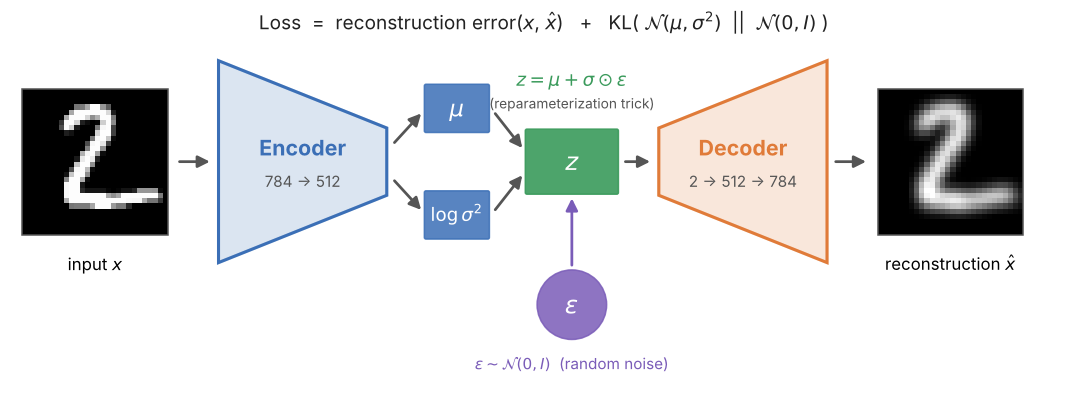

There's a catch: you can't back-propagate through a random sampling step. The **reparameterization trick** rewrites the sample so that the randomness is an *input* instead:

$$z = \mu + \sigma \odot \epsilon, \qquad \epsilon \sim \mathcal{N}(0, I)$$

Now $z$ is a simple differentiable function of $\mu$ and $\sigma$, so gradients flow back into the encoder. $\epsilon$ is just noise we feed in.

In practice the encoder outputs $\log \sigma^2$ (the *log-variance*) instead of $\sigma$. It can be any real number, and $\sigma = \exp(\tfrac{1}{2}\log\sigma^2)$ is then always positive.

### 5.3 The loss: a tug-of-war
$$\mathcal{L}_{\text{VAE}}(x) \;=\; \underbrace{\mathcal{L}_{\text{rec}}(x, \hat{x})}_{\text{reconstruct well}} \;+\; \underbrace{D_{\mathrm{KL}}\Big(\mathcal{N}(\mu, \sigma^2)\ \big\|\ \mathcal{N}(0, I)\Big)}_{\text{stay close to } \mathcal{N}(0,\,I)}$$

For two Gaussians, the KL term has a closed form ([proof](https://statproofbook.github.io/P/norm-kl.html)), summed over the latent dimensions $j$:

$$D_{\mathrm{KL}} = \frac{1}{2} \sum_{j=1}^{d} \Big( \mu_j^2 + \sigma_j^2 - 1 - \log \sigma_j^2 \Big)$$

It is zero exactly when $\mu = 0$ and $\sigma = 1$.

| If we used only… | …the network would | Result |
|---|---|---|
| reconstruction | shrink $\sigma \to 0$ and spread the codes apart | a plain AE, with the same gaps |
| KL | set $\mu = 0,\ \sigma = 1$ for **every** image | the decoder can't tell images apart and outputs the "average digit" |
| **both** | compromise: clouds that overlap and fill $\mathcal{N}(0, I)$ but stay distinguishable | **a smooth, sample-able latent space** ✅ |

*(For the curious: this loss is the negative **ELBO**, the Evidence Lower BOund on $\log p(x)$. Minimising it maximises a lower bound on the likelihood of the data. See Kingma & Welling, 2013.)*

### 5.4 Implementation
Compare this with Section 2. The **decoder is reused unchanged**. Only the encoder gets a second "head".

In [19]:
class VariationalEncoder(nn.Module):
    """x  ->  (μ, log σ²): the parameters of a Gaussian cloud in latent space."""
    def __init__(self, latent_dims):
        super().__init__()
        self.hidden    = nn.Linear(28 * 28, 512)
        self.to_mu     = nn.Linear(512, latent_dims)   # head 1: centre of the cloud
        self.to_logvar = nn.Linear(512, latent_dims)   # head 2: log-variance (size) of the cloud

    def forward(self, x):
        h = F.relu(self.hidden(torch.flatten(x, start_dim=1)))
        return self.to_mu(h), self.to_logvar(h)


class VAE(nn.Module):
    def __init__(self, latent_dims):
        super().__init__()
        self.encoder = VariationalEncoder(latent_dims)
        self.decoder = Decoder(latent_dims)            # the very same Decoder class as before!

    @staticmethod
    def reparameterize(mu, logvar):
        sigma = torch.exp(0.5 * logvar)                # σ = exp(½ · log σ²)
        eps = torch.randn_like(sigma)                  # ε ~ N(0, I): the only random part
        return mu + sigma * eps                        # z ~ N(μ, σ²), differentiable w.r.t. μ and σ

    def forward(self, x):
        mu, logvar = self.encoder(x)
        z = self.reparameterize(mu, logvar)
        return self.decoder(z), mu, logvar


def kl_divergence(mu, logvar):
    """KL( N(μ, σ²) || N(0, I) ), summed over latent dimensions, averaged over the batch."""
    return 0.5 * (mu.pow(2) + logvar.exp() - 1 - logvar).sum() / mu.shape[0]


def vae_loss(model, x, beta=1.0):
    x_hat, mu, logvar = model(x)
    rec = reconstruction_loss(x_hat, x)                # same reconstruction loss as the AE
    kl = kl_divergence(mu, logvar)
    return {"loss": rec + beta * kl, "rec": rec, "kl": kl}

### 5.5 Train it!
It's the same `train` function and the same data, with the new model and loss.

> 🗣 *While it trains:* watch the two terms. `rec` goes down, while `kl` stays small and may even creep up. That's the tug-of-war from 5.3.

In [20]:
torch.manual_seed(SEED)
vae = VAE(LATENT_DIMS).to(device)
vae_history = train(vae, vae_loss)

epoch  1/10 | loss  187.88  rec  182.34  kl    5.54 |  2.3s
epoch  2/10 | loss  166.45  rec  161.17  kl    5.29 |  1.8s
epoch  3/10 | loss  161.99  rec  156.55  kl    5.44 |  1.9s
epoch  4/10 | loss  159.52  rec  153.99  kl    5.53 |  1.8s
epoch  5/10 | loss  157.83  rec  152.22  kl    5.61 |  1.9s
epoch  6/10 | loss  156.57  rec  150.91  kl    5.66 |  1.8s
epoch  7/10 | loss  155.64  rec  149.94  kl    5.70 |  1.8s
epoch  8/10 | loss  154.80  rec  149.07  kl    5.73 |  1.9s
epoch  9/10 | loss  154.13  rec  148.35  kl    5.78 |  1.9s
epoch 10/10 | loss  153.54  rec  147.73  kl    5.81 |  1.9s


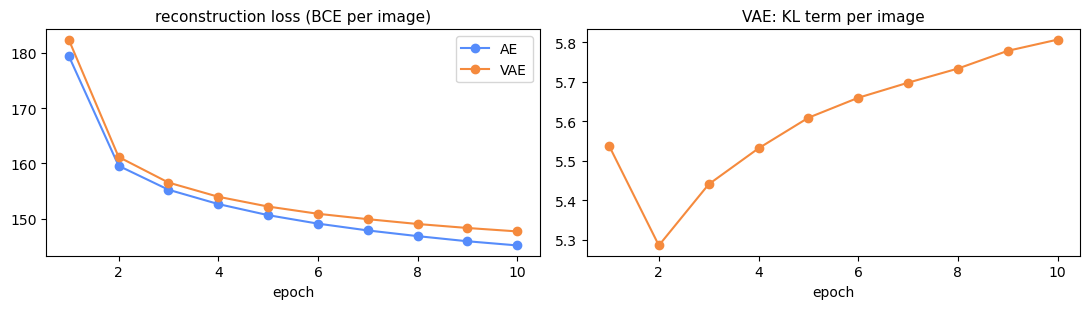

In [21]:
epochs = range(1, len(ae_history["loss"]) + 1)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
axes[0].plot(epochs, ae_history["loss"], "o-", label="AE")
axes[0].plot(epochs, vae_history["rec"], "o-", label="VAE")
axes[0].set_title("reconstruction loss (BCE per image)"); axes[0].set_xlabel("epoch"); axes[0].legend()
axes[1].plot(epochs, vae_history["kl"], "o-", color="C1")
axes[1].set_title("VAE: KL term per image"); axes[1].set_xlabel("epoch")
plt.tight_layout(); plt.show()

The VAE reconstructs a bit **worse** than the plain AE. That's the price of the KL term: the encoder isn't allowed to put codes wherever it likes. Let's see what we get in return.

---
## 6. VAE results

### 6.1 The latent space, side by side
For the VAE we plot each image's **mean** $\mu$. The dashed circles mark 1σ and 2σ of $\mathcal{N}(0, I)$, the distribution we'll sample from.

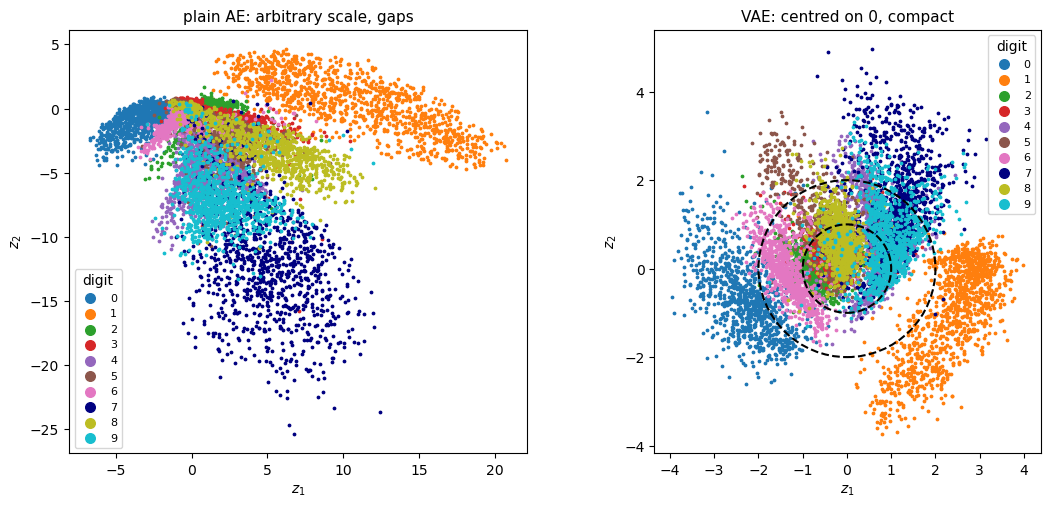

In [22]:
Z_vae = encode(vae, X_test)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
plot_latent(Z_ae,  y_test, ax=axes[0], title="plain AE: arbitrary scale, gaps")
plot_latent(Z_vae, y_test, ax=axes[1], title="VAE: centred on 0, compact")
for radius in (1, 2):
    axes[1].add_patch(plt.Circle((0, 0), radius, fill=False, ls="--", lw=1.5, color="k"))
axes[1].set_aspect("equal")
plt.show()

The single digit from Section 3 is now a **cloud**. Let's look at its $\mu$ and $\sigma$:

In [23]:
with torch.no_grad():
    mu, logvar = vae.encoder(x_single)
sigma = torch.exp(0.5 * logvar)

print(f"our digit's cloud:   centre μ = {mu.squeeze().cpu().numpy().round(2)}   size σ = {sigma.squeeze().cpu().numpy().round(3)}")
print(f"size of the whole map (std of all μ's): {Z_vae.std(0).numpy().round(2)}")

our digit's cloud:   centre μ = [1.24 1.65]   size σ = [0.062 0.097]
size of the whole map (std of all μ's): [1.35 1.07]


Each cloud is **small** compared with the whole map, but it is **never a single point**. There are 60,000 training clouds packed into this small area, so neighbouring clouds overlap. The decoder is trained on random points from all of them, and that is what fills the gaps.

### 6.2 The real test: generating new digits
We feed the **same** random $z \sim \mathcal{N}(0, I)$ from Section 4 into both decoders.

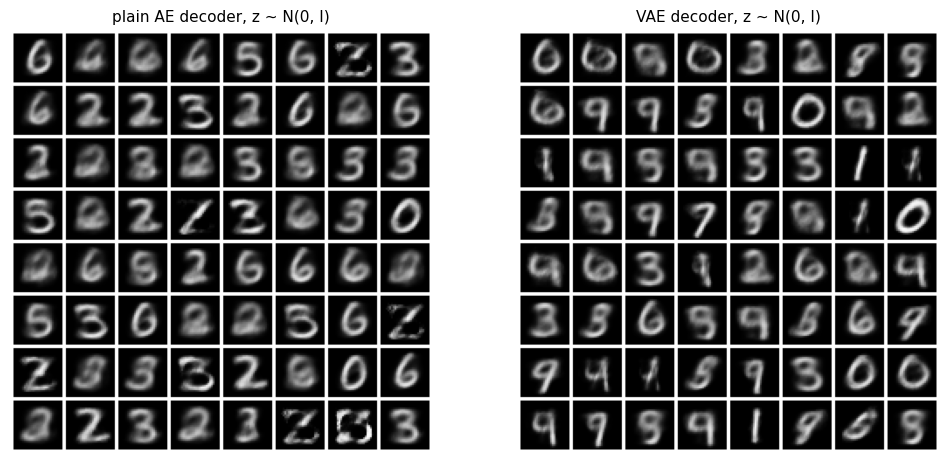

In [24]:
with torch.no_grad():
    samples_vae = vae.decoder(z_random.to(device))     # same z_random as in Section 4!

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
show_images(samples_ae,  ncols=8, ax=axes[0], title="plain AE decoder, z ~ N(0, I)")
show_images(samples_vae, ncols=8, ax=axes[1], title="VAE decoder, z ~ N(0, I)")
plt.show()

The VAE samples are **diverse** and most of them are **recognisable digits**. With a 2-D latent space they're still a bit blurry. Exercise 1 shows how to improve that.

### 6.3 A map of the whole VAE latent space
We decode a grid over $[-3, 3]^2$, which covers most of $\mathcal{N}(0, I)$. Compare it with the AE map in Section 4.

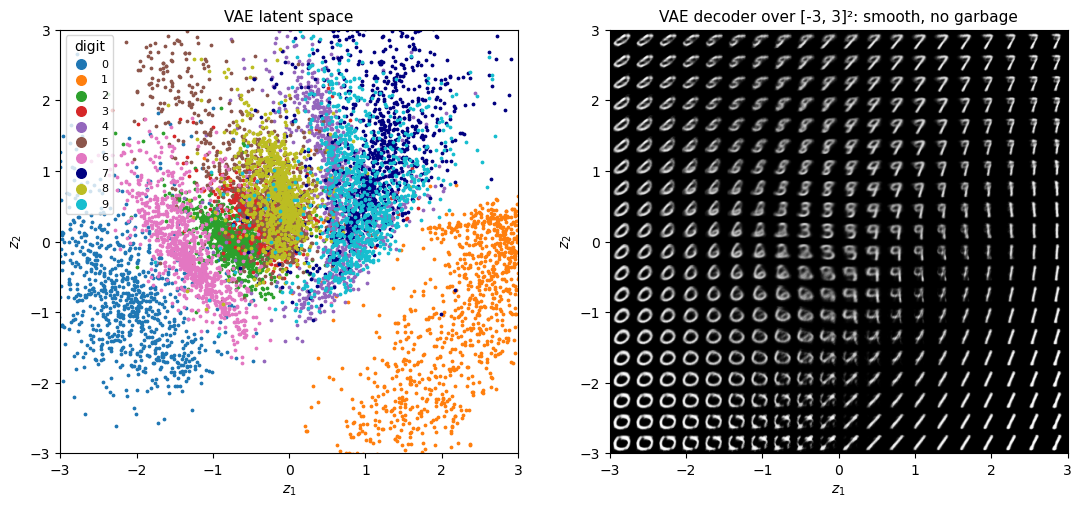

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
plot_latent(Z_vae, y_test, ax=axes[0], title="VAE latent space")
axes[0].set_xlim(-3, 3); axes[0].set_ylim(-3, 3)
plot_latent_grid(vae, (-3, 3), (-3, 3), n=20, ax=axes[1], title="VAE decoder over [-3, 3]²: smooth, no garbage")
plt.show()

### 6.4 Interpolation: walking from one digit to another
We encode two real digits, walk in a **straight line** between their codes and decode each step. A smooth latent space should give a smooth morph.

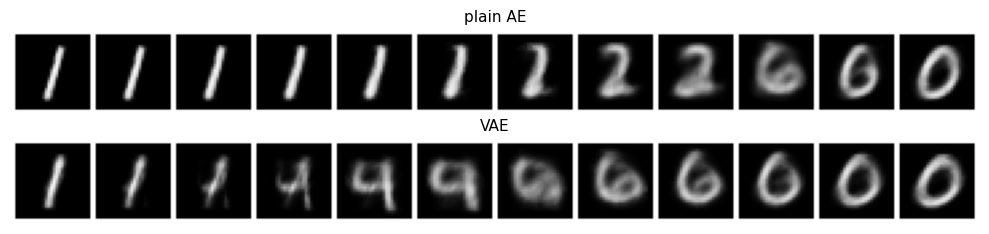

In [26]:
@torch.no_grad()
def interpolate(model, x1, x2, n=12):
    z1, z2 = encode(model, x1), encode(model, x2)          # (1, d) each
    t = torch.linspace(0, 1, n).unsqueeze(1)               # (n, 1)
    z = (1 - t) * z1 + t * z2                              # straight line from z1 to z2
    return model.decoder(z.to(device)).cpu()

x_a = X_test[y_test == 1][0:1]                             # 👈 try other digit pairs!
x_b = X_test[y_test == 0][0:1]

fig, axes = plt.subplots(2, 1, figsize=(10, 2.4))
show_images(interpolate(autoencoder, x_a, x_b), ncols=12, ax=axes[0], title="plain AE")
show_images(interpolate(vae, x_a, x_b),         ncols=12, ax=axes[1], title="VAE")
plt.tight_layout(); plt.show()

🗣 **Discuss:** compare the two rows with the latent maps in 6.1. A straight line between two codes passes through whatever digits lie *between* them on the map, which is why a digit can briefly turn into another class on its way. In the VAE the whole path stays inside the region the decoder was trained on, so there are no holes. With only 2 latent dimensions, though, the path may cross crowded areas where classes overlap, and some frames in the middle can be blurry.

### 6.5 The same interpolation as an animation
This saves a GIF (`interpolation.gif`) with the AE on the left and the VAE on the right.

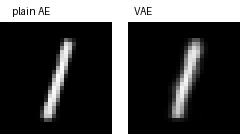

In [27]:
from PIL import Image, ImageDraw
from IPython.display import Image as ShowImage, display

def interpolation_gif(x1, x2, filename="interpolation.gif", n=50, scale=4):
    frames_ae  = interpolate(autoencoder, x1, x2, n).squeeze(1).numpy()
    frames_vae = interpolate(vae, x1, x2, n).squeeze(1).numpy()
    gap = np.ones((28, 4))
    images = []
    for f_ae, f_vae in zip(frames_ae, frames_vae):
        frame = (np.concatenate([f_ae, gap, f_vae], axis=1) * 255).astype(np.uint8)
        img = Image.fromarray(frame).resize((frame.shape[1] * scale, 28 * scale), Image.NEAREST)
        canvas = Image.new("L", (img.width, img.height + 22), 255)
        canvas.paste(img, (0, 22))
        draw = ImageDraw.Draw(canvas)
        draw.text((12, 5), "plain AE", fill=0)
        draw.text((img.width // 2 + 14, 5), "VAE", fill=0)
        images.append(canvas)
    images += images[::-1]                                     # play forwards, then backwards
    images[0].save(filename, save_all=True, append_images=images[1:], duration=50, loop=0)
    return filename

display(ShowImage(filename=interpolation_gif(x_a, x_b)))

**Takeaways from Section 6**
* The KL term pushed the codes into a compact cloud around $\mathcal{N}(0, I)$, so **sampling from $\mathcal{N}(0, I)$ now works**.
* Sampling during training **filled the gaps**, so the whole region we sample from decodes to digit-like images. Compare the two decoder maps.
* The price is slightly blurrier reconstructions than the plain AE. With only 2 latent dimensions, the regions where classes overlap also stay blurry.

**Where you'll meet this again:** Stable Diffusion and many other image generators use a (much bigger, convolutional) **VAE** to compress images into a latent space, then do all the heavy lifting there.

---
## 7. Wrap-up

| | **Autoencoder** | **Variational autoencoder** |
|---|---|---|
| Encoder outputs | a point $z$ | a distribution $\mathcal{N}(\mu, \sigma^2)$ |
| Loss | reconstruction | reconstruction **+ KL** to $\mathcal{N}(0, I)$ |
| Latent space | arbitrary scale, gaps, no guarantees | centred, compact, smooth |
| Reconstructions | sharper | slightly blurrier |
| Generate by sampling $z \sim \mathcal{N}(0, I)$? | ❌ mostly fails | ✅ works |
| Typical uses | compression, denoising, features, anomaly detection | generation, smooth interpolation, representation learning |

**Key ideas to remember**
1. An autoencoder learns **coordinates on the data manifold** by forcing data through a bottleneck. It's non-linear PCA.
2. Reconstruction alone gives no control over the **shape** of the latent space, which is why naive sampling fails.
3. A VAE encodes each input as a **distribution**, samples from it with the **reparameterization trick** and regularises it with a **KL term**. The result is a latent space you can sample from.


### Further reading
* D. Kingma & M. Welling (2013). [*Auto-Encoding Variational Bayes*](https://arxiv.org/abs/1312.6114), the original VAE paper.
* C. Doersch (2016). [*Tutorial on Variational Autoencoders*](https://arxiv.org/abs/1606.05908).
* A. Van de Kleut. [*Variational autoencoders*](https://avandekleut.github.io/vae/), the blog post this notebook started from.

---
## ★ Bonus (homework): a denoising autoencoder

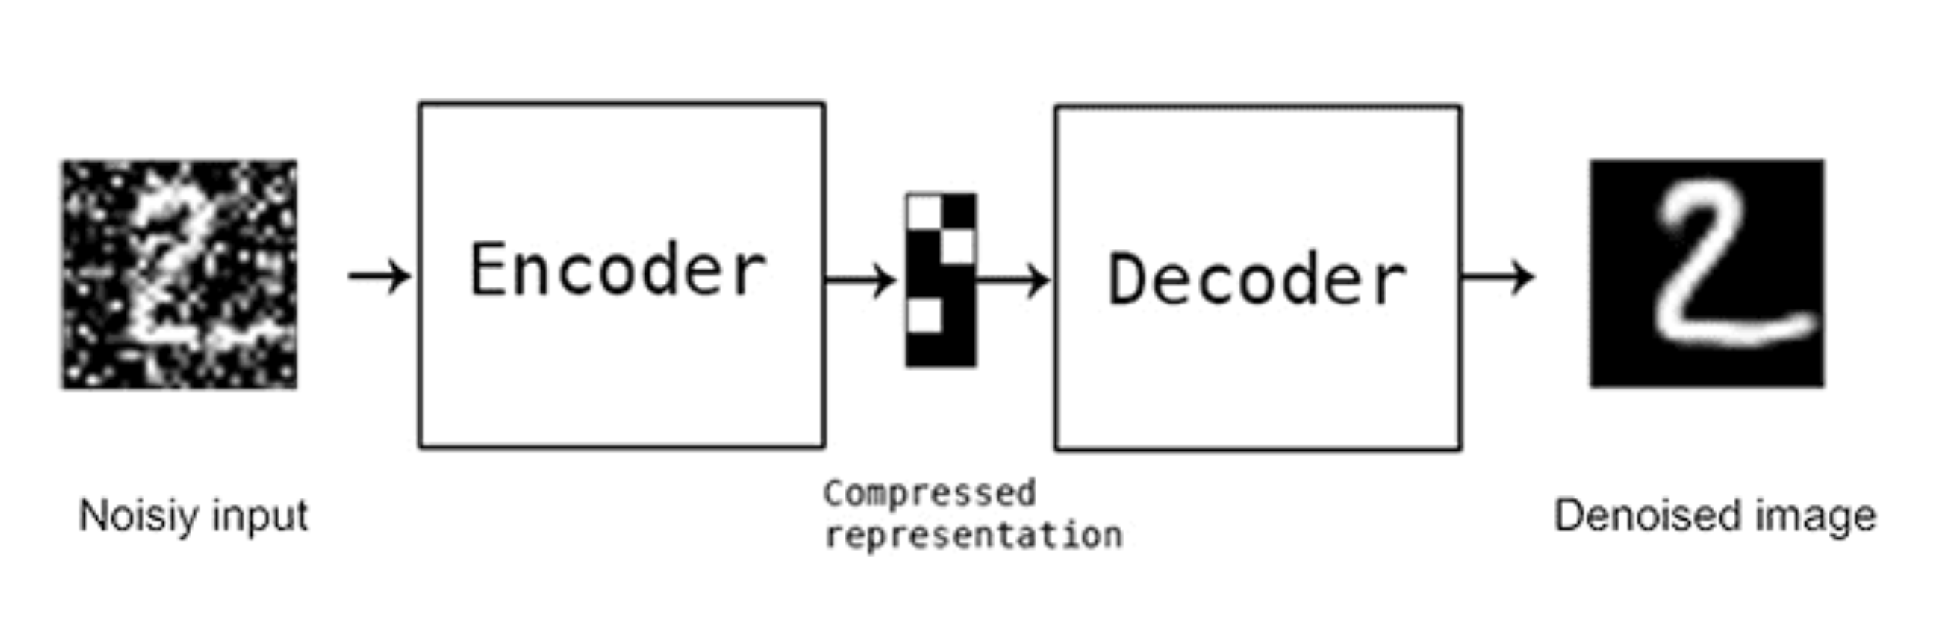

A neat application needs **one** change to the training: corrupt the **input** with noise, but compute the loss against the **clean** image. To reconstruct the clean digit, the network has to learn what digits look like and ignore the noise.

We use a bigger bottleneck (32) here, because we care about image quality and not about plotting.

In [28]:
NOISE = 0.5                                       # noise strength; try 0.3 or 0.8

def add_noise(x, strength=NOISE):
    return (x + strength * torch.randn_like(x)).clamp(0, 1)

def denoising_loss(model, x):
    x_hat = model(add_noise(x))                   # noisy input …
    return {"loss": reconstruction_loss(x_hat, x)}  # … but clean target

torch.manual_seed(SEED)
denoiser = Autoencoder(latent_dims=32).to(device)
_ = train(denoiser, denoising_loss, epochs=5)

epoch  1/5 | loss  150.70 |  1.4s
epoch  2/5 | loss  103.17 |  1.3s
epoch  3/5 | loss   95.16 |  1.3s
epoch  4/5 | loss   91.39 |  1.2s
epoch  5/5 | loss   88.81 |  1.2s


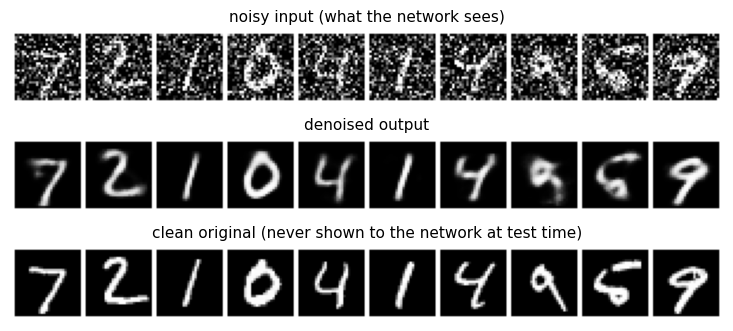

In [29]:
torch.manual_seed(3)
x_clean = X_test[:10]
x_noisy = add_noise(x_clean)
with torch.no_grad():
    x_denoised = denoiser(x_noisy.to(device)).cpu()

fig, axes = plt.subplots(3, 1, figsize=(9, 3.4))
show_images(x_noisy,    ncols=10, ax=axes[0], title="noisy input (what the network sees)")
show_images(x_denoised, ncols=10, ax=axes[1], title="denoised output")
show_images(x_clean,    ncols=10, ax=axes[2], title="clean original (never shown to the network at test time)")
plt.tight_layout(); plt.show()